In [27]:
import numpy as np
import basilisk_runner
import importlib
import dynamics
import utils
import matplotlib.pyplot as plt

In [28]:
importlib.reload(basilisk_runner)
importlib.reload(dynamics)
importlib.reload(utils)

<module 'utils' from '/Users/shash/Documents/Projects/SatelliteRendezvous/utils.py'>

In [29]:
from basilisk_runner import run_orbit
from Basilisk.utilities import orbitalMotion, simIncludeGravBody
from Basilisk.architecture import messaging

In [30]:
sign_test = run_orbit(duration_s=2.0, wheel_torque_test=True)
print("Wheel speeds [rad/s]", sign_test["wheel_speed_rad_s"][-1])
print("Body rates [rad/s]", sign_test["omega_BN_B_chaser"][-1])

pointing = run_orbit(duration_s=120.0)
sigma = pointing["sigma_BN_chaser"]
angle_deg = np.degrees(4 * np.arctan(np.linalg.norm(sigma, axis=1)))

print(f"Initial attitude error {angle_deg[0]:.2f} deg")
print(f"Final attitude error   {angle_deg[-1]:.2f} deg")
print("Peak motor torque per axis [N·m]",
      np.max(np.abs(pointing["wheel_motor_torque_nm"]), axis=0))

Wheel speeds [rad/s] [0.25233141 0.25212997 0.25266786]
Body rates [rad/s] [-0.00100399 -0.00080255 -0.00134044]
Initial attitude error 8.57 deg
Final attitude error   0.00 deg
Peak motor torque per axis [N·m] [0.016 0.024 0.008]


In [31]:
result = run_orbit(
    dt_s=0.025,
    duration_s=2.0,
    rcs_wrench_body=[0.10, 0, 0, 0, 0, 0],
    rcs_pulse_window_s=1.0,
)

t = result["time_s_chaser"]
force = result["rcs_force_body_n"]
print("Sampled body-frame impulse [N·s]", np.trapezoid(force, t, axis=0))

Sampled body-frame impulse [N·s] [0.09 0.   0.  ]


In [32]:
for dt_s in (0.025, 0.0125, 0.00625, 0.003125):
    result = run_orbit(
        dt_s=dt_s,
        duration_s=2.0,
        rcs_wrench_body=[0.10, 0, 0, 0, 0, 0],
        rcs_pulse_window_s=1.0,
    )
    impulse = np.trapezoid(
        result["rcs_force_body_n"],
        result["time_s_chaser"],
        axis=0,
    )
    print(f"dt={dt_s:.6f} s | impulse={impulse} N·s")

dt=0.025000 s | impulse=[0.09 0.   0.  ] N·s
dt=0.012500 s | impulse=[0.0975 0.     0.    ] N·s
dt=0.006250 s | impulse=[0.0975 0.     0.    ] N·s
dt=0.003125 s | impulse=[0.099375 0.       0.      ] N·s


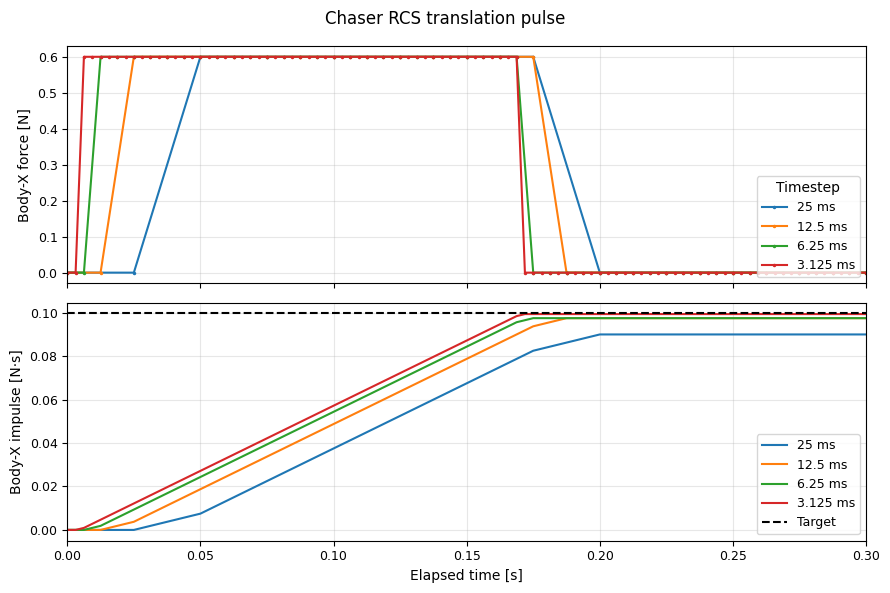

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

from basilisk_runner import run_orbit

fig, (ax_force, ax_impulse) = plt.subplots(
    2, 1, sharex=True, figsize=(9, 6)
)

for dt_s in (0.025, 0.0125, 0.00625, 0.003125):
    result = run_orbit(
        dt_s=dt_s,
        duration_s=2.0,
        rcs_wrench_body=[0.10, 0, 0, 0, 0, 0],
        rcs_pulse_window_s=1.0,
    )

    t = result["time_s_chaser"]
    fx = result["rcs_force_body_n"][:, 0]

    # Integrate between adjacent samples, then accumulate from zero.
    impulse_x = np.r_[0.0, np.cumsum(
        0.5 * (fx[:-1] + fx[1:]) * np.diff(t)
    )]

    label = f"{dt_s * 1000:g} ms"
    ax_force.plot(t, fx, ".-", markersize=3, label=label)
    ax_impulse.plot(t, impulse_x, label=label)

ax_force.set_ylabel("Body-X force [N]")
ax_force.legend(title="Timestep")

ax_impulse.axhline(0.100, color="black", linestyle="--", label="Target")
ax_impulse.set_ylabel("Body-X impulse [N·s]")
ax_impulse.set_xlabel("Elapsed time [s]")
ax_impulse.legend()

ax_impulse.set_xlim(0, 0.3)
for ax in (ax_force, ax_impulse):
    ax.grid(alpha=0.3)

fig.suptitle("Chaser RCS translation pulse")
fig.tight_layout()
plt.show()

In [34]:
cases = {
    "+X translation": [0.10, 0, 0, 0, 0, 0],
    "+Z torque":      [0, 0, 0, 0, 0, 0.08],
}

for name, wrench in cases.items():
    result = run_orbit(
        dt_s=0.003125,
        duration_s=2.0,
        rcs_wrench_body=wrench,
        rcs_pulse_window_s=1.0,
    )
    t = result["time_s_chaser"]
    force_impulse = np.trapezoid(result["rcs_force_body_n"], t, axis=0)
    torque_impulse = np.trapezoid(result["rcs_torque_body_nm"], t, axis=0)

    print(name)
    print("  Force impulse  [N·s]  ", force_impulse)
    print("  Torque impulse [N·m·s]", torque_impulse)

+X translation
  Force impulse  [N·s]   [0.099375 0.       0.      ]
  Torque impulse [N·m·s] [0. 0. 0.]
+Z torque
  Force impulse  [N·s]   [0.       0.000625 0.      ]
  Torque impulse [N·m·s] [0.      0.      0.07975]


+X translation
  Final force impulse  [N·s]   [0.099375 0.       0.      ]
  Final torque impulse [N·m·s] [0. 0. 0.]
+Z torque
  Final force impulse  [N·s]   [0.       0.000625 0.      ]
  Final torque impulse [N·m·s] [0.      0.      0.07975]


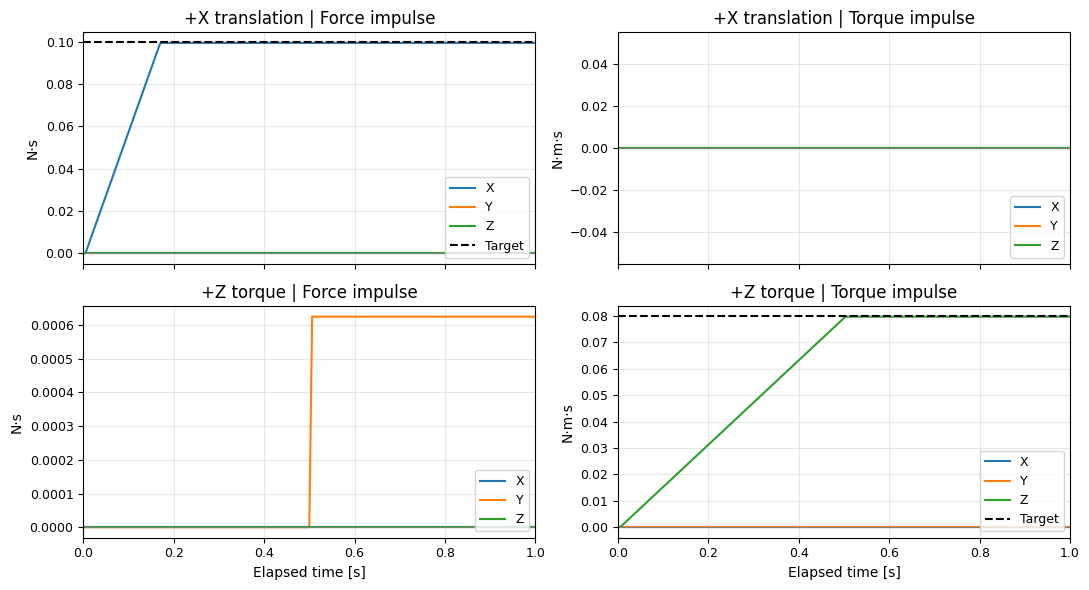

In [35]:
def cumulative_impulse(values, time_s):
    interval_area = (
        0.5 * (values[:-1] + values[1:]) * np.diff(time_s)[:, None]
    )
    return np.vstack((np.zeros((1, 3)), np.cumsum(interval_area, axis=0)))


pulse_window_s = 1.0
cases = [
    ("+X translation", [0.10, 0, 0, 0, 0, 0]),
    ("+Z torque", [0, 0, 0, 0, 0, 0.08]),
]

fig, axes = plt.subplots(2, 2, figsize=(11, 6), sharex=True)

for row, (name, wrench) in enumerate(cases):
    result = run_orbit(
        dt_s=0.003125,
        duration_s=2.0,
        rcs_wrench_body=wrench,
        rcs_pulse_window_s=pulse_window_s,
    )

    t = result["time_s_chaser"]
    force_impulse = cumulative_impulse(result["rcs_force_body_n"], t)
    torque_impulse = cumulative_impulse(result["rcs_torque_body_nm"], t)

    for ax, history, target, title, units in (
        (axes[row, 0], force_impulse, wrench[:3], "Force impulse", "N·s"),
        (axes[row, 1], torque_impulse, wrench[3:], "Torque impulse", "N·m·s"),
    ):
        for i, axis in enumerate("XYZ"):
            ax.plot(t, history[:, i], label=axis)

        ax.axhline(0, color="gray", linewidth=0.8)
        for value in target:
            if value != 0:
                ax.axhline(
                    value * pulse_window_s, color="black",
                    linestyle="--", label="Target",
                )

        ax.set_title(f"{name} | {title}")
        ax.set_ylabel(units)
        ax.grid(alpha=0.3)
        ax.legend()

    print(name)
    print("  Final force impulse  [N·s]  ", force_impulse[-1])
    print("  Final torque impulse [N·m·s]", torque_impulse[-1])

for ax in axes[-1]:
    ax.set_xlabel("Elapsed time [s]")

axes[-1, 0].set_xlim(0, 1.0)
fig.tight_layout()
plt.show()